# IndustryPulseAI SQL analitiği

PostgreSQL’deki AI4I ölçümlerini ve arıza etiketlerini inceleyeceğiz. Sorgular [SQL dosyasından](../sql/02_analytics_queries.sql) okunur. Python mevcut bağlantı modülünü kullanır ve sorguları salt okunur transaction’larda yürütür. Sonuçlar Pandas DataFrame olarak gösterilir.

Notebook’u proje kökünden veya `notebooks` klasöründen, projenin Python ortamıyla çalıştırabilirsiniz.

In [1]:
from pathlib import Path
import re
import sys

import matplotlib.pyplot as plt
import pandas as pd
import psycopg
from IPython.display import Markdown, display

root = Path.cwd()
if not (root / "sql" / "02_analytics_queries.sql").is_file():
    root = root.parent
sys.path.insert(0, str(root))

from src.database import connect

sql_text = (root / "sql" / "02_analytics_queries.sql").read_text(encoding="utf-8")
sections = re.split(r"^-- name: (\w+)\s*$", sql_text, flags=re.MULTILINE)
queries = dict(zip(sections[1::2], (text.strip() for text in sections[2::2]), strict=True))

def query_frame(name):
    """Sorguyu salt okunur transaction ile çalıştır ve sütun adlarını koru."""
    statement = queries[name]
    display(Markdown("```sql\n" + statement + "\n```"))
    try:
        with connect() as connection:
            connection.read_only = True
            cursor = connection.execute(statement)
            return pd.DataFrame(cursor.fetchall(), columns=[col.name for col in cursor.description])
    except (psycopg.Error, KeyError, ValueError):
        raise RuntimeError("PostgreSQL sorgusu çalıştırılamadı. Bağlantıyı ve şemayı kontrol edin.") from None

def bar_chart(values, title, ylabel):
    ax = values.astype(float).plot.bar(color="#356794", figsize=(7, 3.4), rot=0)
    ax.set(title=title, xlabel="", ylabel=ylabel)
    ax.bar_label(ax.containers[0], fmt="%g", padding=3)
    ax.margins(y=0.18)
    plt.tight_layout()
    plt.show()

## Toplam kayıt, arıza sayısı ve genel arıza oranı

SELECT döndürülecek alanları seçer. COUNT etiketli ölçümleri sayar. Hedef 0 veya 1 olduğu için SUM arızalı kayıt sayısını, AVG ise arıza payını verir. 100 ile çarparak yüzdeyi buluruz. MIN ve MAX, torkun gözlenen aralığını gösterir.

```sql
-- COUNT satırları, SUM arızaları sayar. AVG üzerinden oran, MIN/MAX ile tork aralığı.
SELECT count(*) AS total_records,
       sum(machine_failure) AS failure_count,
       count(*) FILTER (WHERE machine_failure = 0) AS normal_count,
       round(100 * avg(machine_failure), 2) AS failure_rate_pct,
       round(avg(torque), 5) AS avg_torque_nm,
       min(torque) AS min_torque_nm,
       max(torque) AS max_torque_nm
FROM public.ml_training_data;
```

,total_records,failure_count,normal_count,failure_rate_pct,avg_torque_nm,min_torque_nm,max_torque_nm
0,10000,339,9661,3.39,39.98691,3.8,76.6


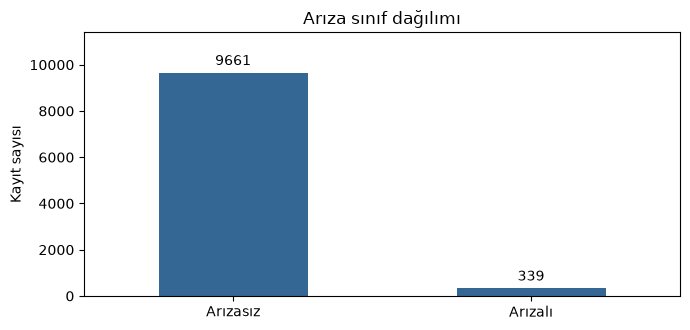

In [2]:
overview = query_frame("overview")
display(overview)
row = overview.iloc[0]
bar_chart(pd.Series({"Arızasız": row.normal_count, "Arızalı": row.failure_count}),
          "Arıza sınıf dağılımı", "Kayıt sayısı")

## Ürün tipine göre arıza oranları

LEFT JOIN, ürün kataloğundaki her tipi korur. GROUP BY aynı tipteki satırları birleştirir. Oranın paydası etiketli ölçümlerdir. Etiketsiz bir tipin oranı boş kalır. Bu sorgu farklı büyüklükteki grupları yüzde üzerinden karşılaştırır.

```sql
-- LEFT JOIN ile ölçümü bulunmayan tipler korunur. Payda, etiketli ölçüm sayısıdır.
SELECT p.type_code, p.type_name,
       count(s.udi) AS reading_count,
       count(f.udi) AS labeled_count,
       coalesce(sum(f.machine_failure), 0) AS failure_count,
       round(100 * avg(f.machine_failure), 2) AS failure_rate_pct
FROM public.product_types AS p
LEFT JOIN public.sensor_readings AS s ON s.type_code = p.type_code
LEFT JOIN public.failure_records AS f ON f.udi = s.udi
GROUP BY p.type_code, p.type_name
ORDER BY p.type_code;
```

,type_code,type_name,reading_count,labeled_count,failure_count,failure_rate_pct
0,H,High,1003,1003,21,2.09
1,L,Low,6000,6000,235,3.92
2,M,Medium,2997,2997,83,2.77


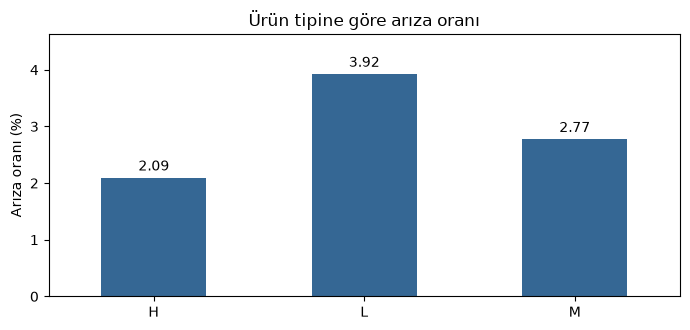

In [3]:
product_rates = query_frame("product_rates")
display(product_rates)
bar_chart(product_rates.set_index("type_code")["failure_rate_pct"],
          "Ürün tipine göre arıza oranı", "Arıza oranı (%)")

## Yeterli gözlemi olan ürün tipleri

GROUP BY önce her ürün tipindeki ölçümleri sayar. HAVING yalnızca en az 2.000 ölçümü olan grupları tutar. WHERE tek tek satırlara, HAVING hesaplanan gruplara uygulanır. Bu örnek, daha büyük örneklemli tipleri ayırır.

In [4]:
product_groups = query_frame("product_groups")
display(product_groups)

```sql
-- HAVING, kayıt sayısı hesaplandıktan sonra ürün tipi gruplarını filtreler.
SELECT type_code, count(*) AS reading_count
FROM public.sensor_readings
GROUP BY type_code
HAVING count(*) >= 2000
ORDER BY reading_count DESC, type_code;
```

,type_code,reading_count
0,L,6000
1,M,2997


## Arızalı ve arızasız ölçümlerin ortalamaları

INNER JOIN, UDI üzerinden yalnızca ölçümü ve etiketi eşleşen satırları alır. GROUP BY iki arıza sınıfını ayırır. AVG her sensörü kendi biriminde özetler. Bu karşılaştırma iki grubun gözlenen farklarını gösterir.

In [5]:
sensor_means = query_frame("sensor_means")
display(sensor_means)

```sql
-- INNER JOIN yalnızca ölçümü ve etiketi eşleşen satırları alır.
SELECT f.machine_failure, count(*) AS record_count,
       round(avg(s.air_temperature), 2) AS air_temperature_k,
       round(avg(s.process_temperature), 2) AS process_temperature_k,
       round(avg(s.rotational_speed), 2) AS rotational_speed_rpm,
       round(avg(s.torque), 2) AS torque_nm,
       round(avg(s.tool_wear), 2) AS tool_wear_min
FROM public.sensor_readings AS s
INNER JOIN public.failure_records AS f ON f.udi = s.udi
GROUP BY f.machine_failure
ORDER BY f.machine_failure;
```

,machine_failure,record_count,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min
0,0,9661,299.97,310.00,1540.26,39.63,106.69
1,1,339,300.89,310.29,1496.49,50.17,143.78


## En yüksek torka sahip 10 kayıt

ORDER BY torku büyükten küçüğe sıralar. Eşit tork değerlerinde UDI sıralamayı belirler. LIMIT ilk on kaydı döndürür. Bu liste en yüksek ölçümleri tek tek incelemek için kullanılır.

In [6]:
top_torque = query_frame("top_torque")
display(top_torque)

```sql
-- ORDER BY en yüksek torku öne alır, UDI eşitlikleri çözer. LIMIT ilk 10 satırı verir.
SELECT udi, product_id, type_code, torque AS torque_nm
FROM public.sensor_readings
ORDER BY torque DESC, udi
LIMIT 10;
```

,udi,product_id,type_code,torque_nm
0,7764,L54943,L,76.6
1,881,M15740,M,76.2
2,9085,L56264,L,75.4
3,1325,M16184,M,74.5
4,6526,L53705,L,73.6
5,3001,H32414,H,72.8
6,8583,M23442,M,72.0
7,7570,L54749,L,71.8
8,604,L47783,L,71.6
9,5616,M20475,M,71.3


## Takım aşınmasına göre örnek risk grupları

CASE WHEN aşınmayı düşük (<100 dk), orta (100–199 dk) ve yüksek (≥200 dk) diye etiketler. WITH ile tanımlanan CTE bu geçici sorgu sonucunu adlandırır. Dış sorgu her grubun geçmiş arıza oranını hesaplar. **Eşikler yalnızca öğretici örnektir ve gerçek bir risk modeli oluşturmaz.**

```sql
-- Öğretici aşınma eşikleri. Gruplar gerçek bir risk modelini temsil etmez.
WITH grouped_wear AS (
    SELECT machine_failure,
           CASE WHEN tool_wear < 100 THEN 'Düşük'
                WHEN tool_wear < 200 THEN 'Orta'
                ELSE 'Yüksek'
           END AS wear_group
    FROM public.ml_training_data
)
SELECT wear_group, count(*) AS labeled_count,
       sum(machine_failure) AS failure_count,
       round(100 * avg(machine_failure), 2) AS failure_rate_pct
FROM grouped_wear
GROUP BY wear_group
ORDER BY min(CASE wear_group WHEN 'Düşük' THEN 1 WHEN 'Orta' THEN 2 ELSE 3 END);
```

,wear_group,labeled_count,failure_count,failure_rate_pct
0,Düşük,4620,103,2.23
1,Orta,4579,113,2.47
2,Yüksek,801,123,15.36


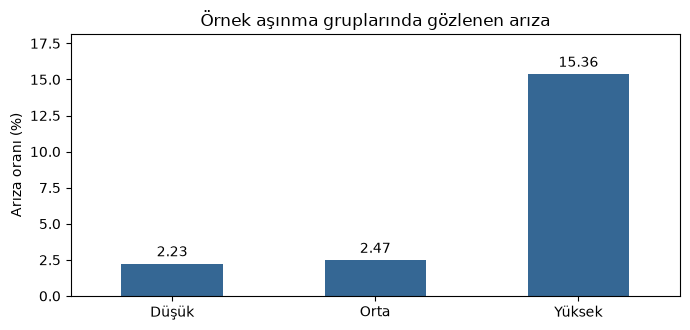

In [7]:
wear_groups = query_frame("wear_groups")
display(wear_groups)
bar_chart(wear_groups.set_index("wear_group")["failure_rate_pct"],
          "Örnek aşınma gruplarında gözlenen arıza", "Arıza oranı (%)")

## Her ürün tipi içinde tork sıralaması

Pencere fonksiyonları her ölçüm satırını koruyarak ürün tipi içinde hesap yapar. PARTITION BY tipleri ayırır. ROW_NUMBER her satıra benzersiz sıra verir ve eşitlikte UDI kullanır. RANK, eşit torklara aynı sırayı verir ve sonraki sırada boşluk bırakabilir. DENSE_RANK sıraları boşluksuz verir. AVG OVER tip ortalamasını her satıra ekler. CTE, sıralama hesaplandıktan sonra tip başına ilk 10 satırın seçilmesini sağlar.

In [8]:
torque_ranks = query_frame("torque_ranks")
display(torque_ranks)

```sql
-- Her tipin ilk 10 satırı. Pencere sıralaması tip başına tüm ölçümler üzerinden yapılır.
WITH ranked AS (
    SELECT udi, type_code, torque AS torque_nm,
           row_number() OVER (PARTITION BY type_code ORDER BY torque DESC, udi) AS row_no,
           rank() OVER (PARTITION BY type_code ORDER BY torque DESC) AS torque_rank,
           dense_rank() OVER (PARTITION BY type_code ORDER BY torque DESC) AS dense_torque_rank,
           round(avg(torque) OVER (PARTITION BY type_code), 2) AS type_avg_torque_nm
    FROM public.sensor_readings
)
SELECT udi, type_code, torque_nm, row_no, torque_rank, dense_torque_rank, type_avg_torque_nm
FROM ranked
WHERE row_no <= 10
ORDER BY type_code, row_no;
```

,udi,type_code,torque_nm,row_no,torque_rank,dense_torque_rank,type_avg_torque_nm
0,3001,H,72.8,1,1,1,39.84
1,5049,H,68.6,2,2,2,39.84
2,6519,H,67.9,3,3,3,39.84
3,5910,H,65.3,4,4,4,39.84
4,3493,H,63.6,5,5,5,39.84
5,3502,H,63.6,6,5,5,39.84
6,8423,H,63.0,7,7,6,39.84
7,1856,H,62.8,8,8,7,39.84
8,1401,H,62.7,9,9,8,39.84
9,4079,H,62.4,10,10,9,39.84


## Arıza türlerinin görülme sıklıkları

SUM her arıza bayrağındaki 1 değerlerini toplar. CTE içindeki toplamlar VALUES ile tür başına bir satıra açılır. Bir kayıtta birden fazla bayrak bulunabilir. Bayraklar kaynak veride ayrı göstergelerdir ve toplamları genel arıza sayısına eşit olmak zorunda değildir.

```sql
-- Her bayrak bağımsız sayılır. Aynı satırda birden fazla bayrak açık olabilir.
WITH totals AS (
    SELECT sum(twf) AS twf, sum(hdf) AS hdf, sum(pwf) AS pwf,
           sum(osf) AS osf, sum(rnf) AS rnf
    FROM public.failure_records
)
SELECT mode.failure_type, mode.record_count
FROM totals
CROSS JOIN LATERAL (
    VALUES ('TWF', twf), ('HDF', hdf), ('PWF', pwf), ('OSF', osf), ('RNF', rnf)
) AS mode(failure_type, record_count)
ORDER BY mode.record_count DESC, mode.failure_type;
```

,failure_type,record_count
0,HDF,115
1,OSF,98
2,PWF,95
3,TWF,46
4,RNF,19


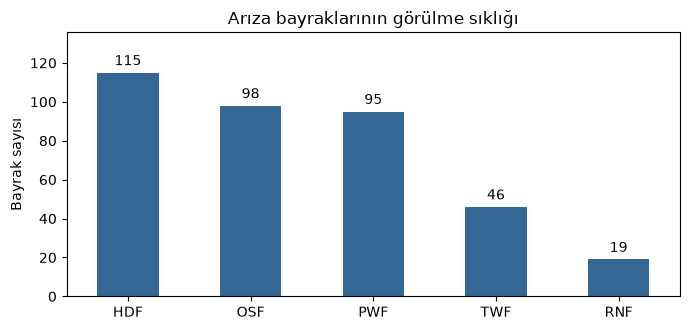

In [9]:
failure_modes = query_frame("failure_modes")
display(failure_modes)
bar_chart(failure_modes.set_index("failure_type")["record_count"],
          "Arıza bayraklarının görülme sıklığı", "Bayrak sayısı")

## Genel tork ortalamasının üzerindeki kayıtlar

Parantez içindeki alt sorgu (subquery) tüm ölçümlerin ortalama torkunu hesaplar. Dış sorgudaki WHERE, torku bu ortalamayı aşan kayıtları seçer. DataFrame tüm sonucu içerir. Önizleme ilk 10 satırı gösterir.

In [10]:
above_average = query_frame("above_average")
display(above_average.head(10))
print(f"Ortalamanın üzerindeki kayıt sayısı: {len(above_average):,}")

```sql
-- Alt sorgu genel tork ortalamasını üretir. WHERE bu değeri aşan ölçümleri seçer.
SELECT udi, product_id, type_code, torque AS torque_nm
FROM public.sensor_readings
WHERE torque > (SELECT avg(torque) FROM public.sensor_readings)
ORDER BY torque DESC, udi;
```

,udi,product_id,type_code,torque_nm
0,7764,L54943,L,76.6
1,881,M15740,M,76.2
2,9085,L56264,L,75.4
3,1325,M16184,M,74.5
4,6526,L53705,L,73.6
5,3001,H32414,H,72.8
6,8583,M23442,M,72.0
7,7570,L54749,L,71.8
8,604,L47783,L,71.6
9,5616,M20475,M,71.3


Ortalamanın üzerindeki kayıt sayısı: 5,060


## EXPLAIN ANALYZE ile tek kayda erişim

EXPLAIN ANALYZE sorguyu gerçekten çalıştırır ve planın tahmini maliyetiyle ölçülen süre ve satır sayılarını gösterir. BUFFERS sayfa erişimlerini ekler. UDI birincil anahtar olduğundan, belirli bir UDI için Index Scan indeksten satırın konumunu bulup gerekli tablo verisini okur.

In [11]:
plan_by_udi = query_frame("plan_by_udi")
display(plan_by_udi)
print(plan_by_udi["QUERY PLAN"].str.cat(sep="\n"))

```sql
-- Seçici bir koşulda birincil anahtar indeksinin plan içindeki rolü.
EXPLAIN (ANALYZE, BUFFERS)
SELECT udi, torque
FROM public.sensor_readings
WHERE udi = 1000;
```

,QUERY PLAN
0,Index Scan using sensor_readings_pkey on senso...
1,Index Cond: (udi = 1000)
2,Buffers: shared hit=3
3,Planning:
4,Buffers: shared hit=82
5,Planning Time: 0.337 ms
6,Execution Time: 0.079 ms


Index Scan using sensor_readings_pkey on sensor_readings  (cost=0.29..8.30 rows=1 width=10) (actual time=0.015..0.016 rows=1 loops=1)
  Index Cond: (udi = 1000)
  Buffers: shared hit=3
Planning:
  Buffers: shared hit=82
Planning Time: 0.337 ms
Execution Time: 0.079 ms


## EXPLAIN ANALYZE ile tüm tablo ortalaması

Sequential Scan (planda Seq Scan), tablo sayfalarını sırayla okur. Tüm satırların torku ortalamaya katkı sağladığı için bu plan mantıklıdır. Küçük veri setinde indeks kullanılmaması her zaman performans problemi değildir. Planı okurken satır sayısını, gerçek süreyi ve erişilen sayfaları birlikte değerlendirin.

In [12]:
plan_full_average = query_frame("plan_full_average")
display(plan_full_average)
print(plan_full_average["QUERY PLAN"].str.cat(sep="\n"))

```sql
-- Tüm ölçümleri kapsayan bir toplama işleminin planı.
EXPLAIN (ANALYZE, BUFFERS)
SELECT avg(torque)
FROM public.sensor_readings;
```

,QUERY PLAN
0,Aggregate (cost=219.00..219.01 rows=1 width=3...
1,Buffers: shared hit=94
2,-> Seq Scan on sensor_readings (cost=0.00....
3,Buffers: shared hit=94
4,Planning:
5,Buffers: shared hit=78
6,Planning Time: 0.192 ms
7,Execution Time: 1.595 ms


Aggregate  (cost=219.00..219.01 rows=1 width=32) (actual time=1.538..1.539 rows=1 loops=1)
  Buffers: shared hit=94
  ->  Seq Scan on sensor_readings  (cost=0.00..194.00 rows=10000 width=6) (actual time=0.007..0.498 rows=10000 loops=1)
        Buffers: shared hit=94
Planning:
  Buffers: shared hit=78
Planning Time: 0.192 ms
Execution Time: 1.595 ms


## Mevcut EDA ile karşılaştırma

[EDA notebook’u](01_exploratory_data_analysis.ipynb) ham CSV üzerinden 10.000 kayıt, 339 arıza ve %3,39 genel arıza oranı bulmuştu. Ürün tipi bazında H %2,09, L %3,92 ve M %2,77 idi. Arızalı ölçümlerde ortalama tork ve takım aşınması daha yüksek, dönüş hızı daha düşüktü. Aşağıdaki kontrol ham CSV’den aynı özetleri yeniden hesaplar ve SQL sonuçlarıyla karşılaştırır. Bulgular gözlenen grupları betimler.

In [13]:
from math import isclose

raw = pd.read_csv(root / "data" / "raw" / "ai4i2020.csv")
target = raw["Machine failure"]
sensor_map = {
    "Air temperature [K]": "air_temperature_k",
    "Process temperature [K]": "process_temperature_k",
    "Rotational speed [rpm]": "rotational_speed_rpm",
    "Torque [Nm]": "torque_nm",
    "Tool wear [min]": "tool_wear_min",
}
eda_types = raw.groupby("Type")["Machine failure"].agg(["size", "sum", "mean"])
sql_types = product_rates.set_index("type_code")
eda_means = raw.groupby("Machine failure")[list(sensor_map)].mean().rename(columns=sensor_map)
sql_means = sensor_means.set_index("machine_failure")[list(sensor_map.values())].astype(float)
modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
row = overview.iloc[0]

checks = {
    "Toplam ve sınıf sayıları": (row.total_records == len(raw)
        and row.failure_count == target.sum() and row.normal_count == (target == 0).sum()),
    "Genel arıza oranı": isclose(float(row.failure_rate_pct), target.mean() * 100, abs_tol=0.005),
    "Ürün tipi sayıları ve oranları": (
        sql_types["labeled_count"].tolist() == eda_types["size"].tolist()
        and sql_types["failure_count"].tolist() == eda_types["sum"].tolist()
        and (sql_types["failure_rate_pct"].astype(float).sub(eda_types["mean"] * 100).abs() < 0.005).all()
    ),
    "Arıza durumuna göre sensör ortalamaları": (sql_means.sub(eda_means).abs() < 0.005).all().all(),
    "Genel tork ortalaması ve uçları": (
        isclose(float(row.avg_torque_nm), raw["Torque [Nm]"].mean(), abs_tol=0.000005)
        and isclose(float(row.min_torque_nm), raw["Torque [Nm]"].min())
        and isclose(float(row.max_torque_nm), raw["Torque [Nm]"].max())
    ),
    "Arıza türü sayıları": failure_modes.set_index("failure_type")["record_count"].to_dict()
        == raw[modes].sum().to_dict(),
}
display(pd.Series(checks, name="EDA ile uyumlu").to_frame())
assert all(checks.values()), [name for name, passed in checks.items() if not passed]

,EDA ile uyumlu
Toplam ve sınıf sayıları,True
Genel arıza oranı,True
Ürün tipi sayıları ve oranları,True
Arıza durumuna göre sensör ortalamaları,True
Genel tork ortalaması ve uçları,True
Arıza türü sayıları,True
